In [39]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from pathlib import Path
# Style settings
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})

# Get the current working directory
current_dir = Path.cwd()

# If the notebook is running inside the 'notebooks' folder, step up one level to the parent dir
if current_dir.name == "notebooks":
    os.chdir(current_dir.parent)
    print(f"Changed working directory to: {Path.cwd()}")
else:
    print(f"Working directory is already: {Path.cwd()}")

# CONFIG
zero_shot_1_7_path  = "data/05_archive/temp13_without_dist/2000_run/report_zero_shot_2000.json"
few_shot_1_7_path  = "data/05_archive/temp13_without_dist/2000_run/report_few_shot_2000.json"
template_1_7_path  = "data/05_archive/temp13_without_dist/2000_run/report_template_2000.json"
entity_1_7_path  = "data/05_archive/temp13_without_dist/2000_run/report_entity_2000.json"


# Load the reports into a centralized dictionary
reports = {}
paths = {
    "Zero_shot": zero_shot_1_7_path,
    "Few_shot": few_shot_1_7_path,
    "Template": template_1_7_path,
    "Entity": entity_1_7_path,
}

for strategy, path in paths.items():
    with open(path, "r", encoding="utf-8") as f:
        reports[strategy] = json.load(f)

print("All reports loaded successfully!")

strategies = ["Zero_shot", "Few_shot", "Template", "Entity"]

Working directory is already: C:\Users\Matej\Documents\GitHub\MasterThesis\MasterThesis
All reports loaded successfully!


## Diversity Analysis - Pairwise and Closest Match Metrics

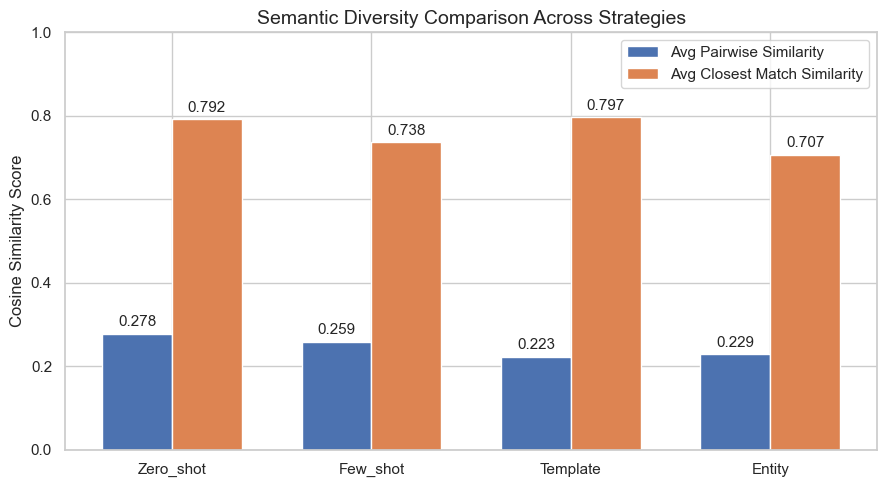

In [40]:
# Extract metrics
avg_pairwise = [reports[s]["Diversity"]["all_pairs_similarity"]["avg_pairwise_sim"] for s in strategies]
avg_closest  = [reports[s]["Diversity"]["closest_match_similarity"]["avg_closest_match"] for s in strategies]

x = np.arange(len(strategies))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, avg_pairwise, width, label='Avg Pairwise Similarity', color='#4c72b0')
rects2 = ax.bar(x + width/2, avg_closest, width, label='Avg Closest Match Similarity', color='#dd8452')

ax.set_ylabel('Cosine Similarity Score')
ax.set_title('Semantic Diversity Comparison Across Strategies')
ax.set_xticks(x)
ax.set_xticklabels(strategies)
ax.set_ylim(0, 1.0)
ax.legend()

# Add value labels on top of the bars
ax.bar_label(rects1, padding=3, fmt='%.3f')
ax.bar_label(rects2, padding=3, fmt='%.3f')

plt.tight_layout()
plt.show()

## Triplet Density Analysis - Averages and Triplet Count Distributions

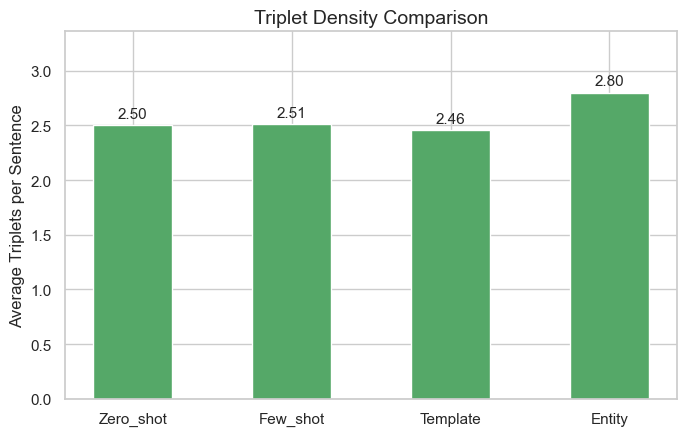

In [41]:
avg_triplets = [reports[s]["Statistical"]["triplet_density"]["average_triplets"] for s in strategies]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(strategies, avg_triplets, color='#55a868', width=0.5)

ax.set_ylabel('Average Triplets per Sentence')
ax.set_title('Triplet Density Comparison')
ax.set_ylim(0, max(avg_triplets) * 1.2)

ax.bar_label(bars, padding=3, fmt='%.2f')

plt.tight_layout()
plt.show()

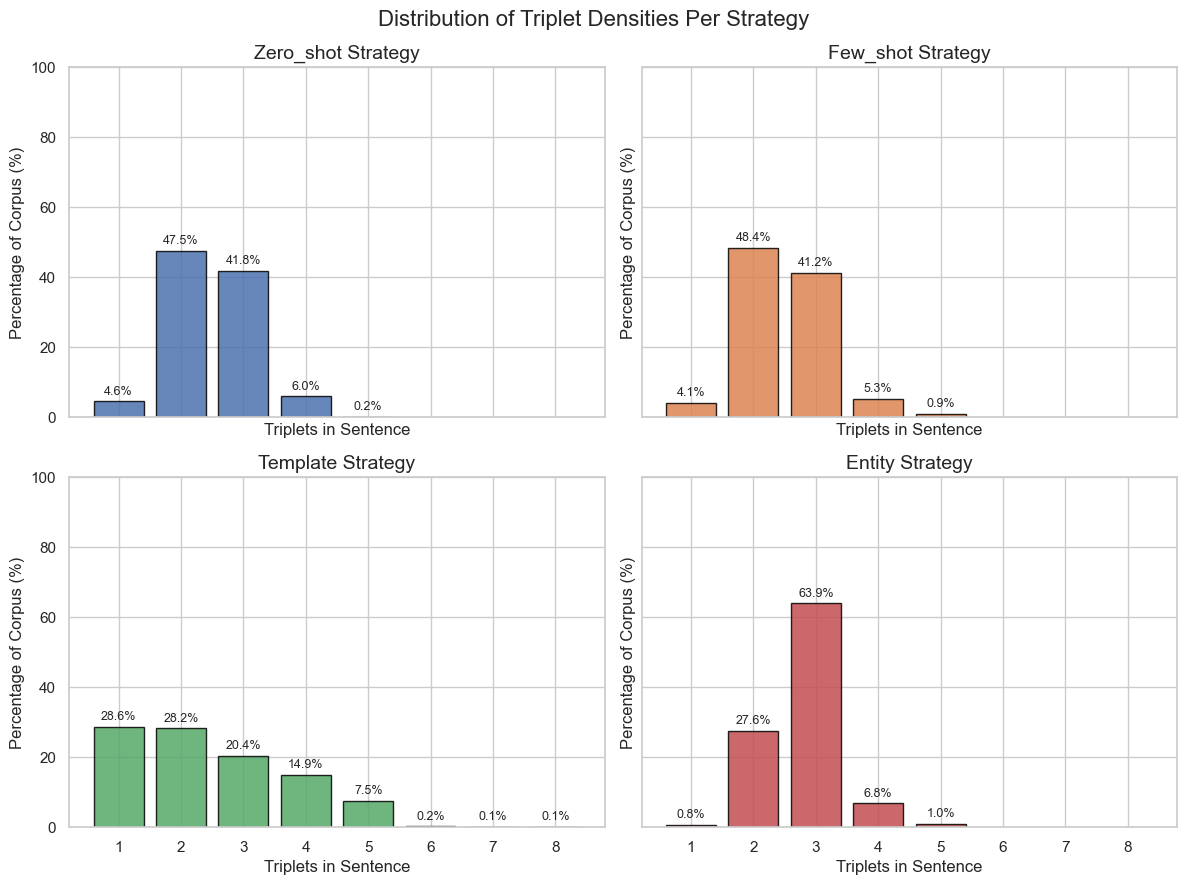

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
axes = axes.flatten()

# Cohesive color palette for the 4 subplots
colors = ['#4c72b0', '#dd8452', '#55a868', '#c44e52']

for i, strategy in enumerate(strategies):
    ax = axes[i]
    density_pcts = reports[strategy]["Statistical"]["triplet_density"]["percentages"]

    # Standardize keys by removing the "_triplets" suffix for cleaner x-axis labels
    clean_keys = [k.split('_')[0] for k in density_pcts.keys()]
    values = list(density_pcts.values())

    bars = ax.bar(clean_keys, values, color=colors[i], alpha=0.85, edgecolor='black')

    ax.set_title(f"{strategy} Strategy")
    ax.set_ylabel('Percentage of Corpus (%)')
    ax.set_xlabel('Triplets in Sentence')
    ax.set_ylim(0, 100)
    ax.bar_label(bars, padding=3, fmt='%.1f%%', fontsize=9)

plt.suptitle('Distribution of Triplet Densities Per Strategy', fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Grammatical Correctness

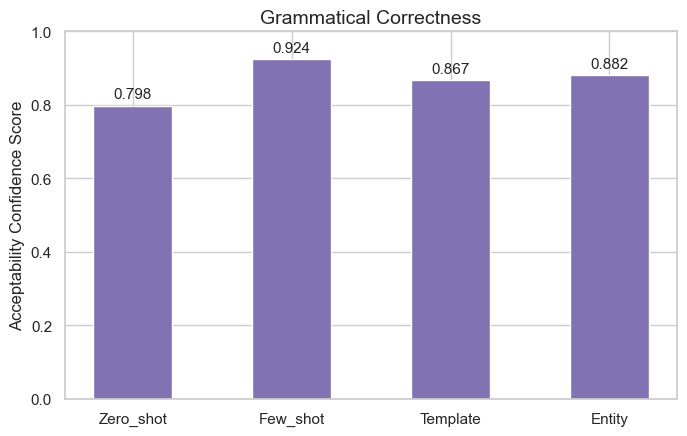

In [43]:
avg_grammar = [reports[s]["Grammar"]["grammar"]["avg_score"] for s in strategies]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(strategies, avg_grammar, color='#8172b3', width=0.5)

ax.set_ylabel('Acceptability Confidence Score')
ax.set_title('Grammatical Correctness')
ax.set_ylim(0, 1.0)

ax.bar_label(bars, padding=3, fmt='%.3f')

plt.tight_layout()
plt.show()

## Adequacy, Adherence & Schema Compliance

Plot A: Schema Compliance (Ontology Violations)

Plot B: Entity/Template Constraint Adherence



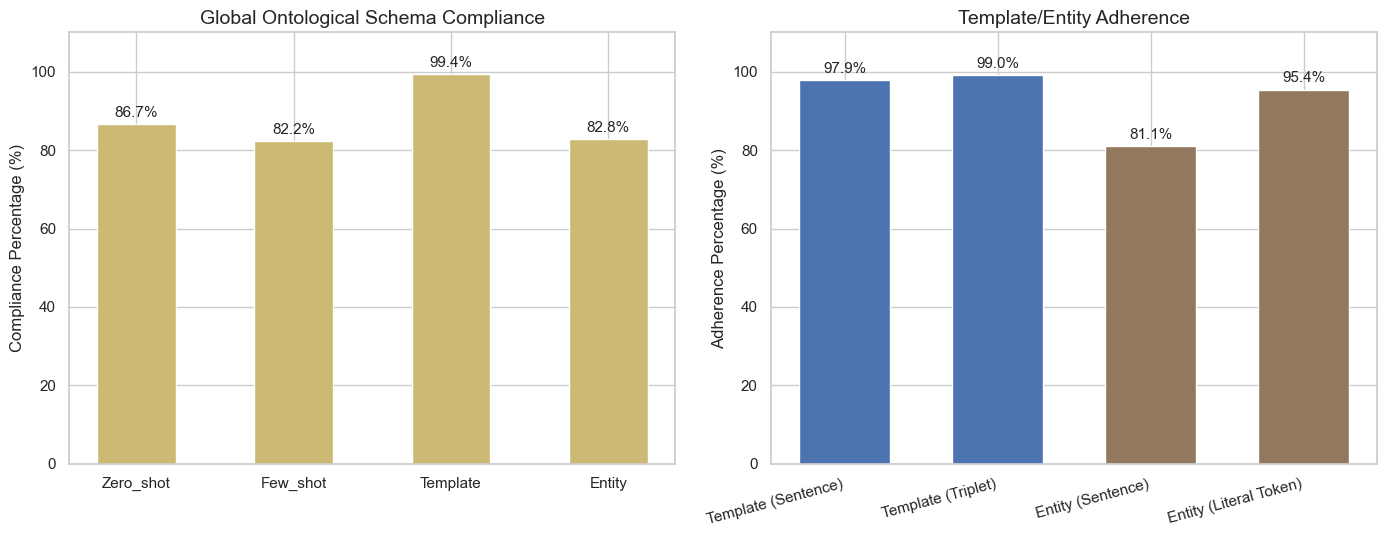

In [44]:
compliance_scores = [reports[s]["Adequacy"]["schema_compliance"]["compliance_percentage"] for s in strategies]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

bars1 = ax1.bar(strategies, compliance_scores, color='#ccb974', width=0.5)
ax1.set_ylabel('Compliance Percentage (%)')
ax1.set_title('Global Ontological Schema Compliance')
ax1.set_ylim(0, 110)
ax1.bar_label(bars1, padding=3, fmt='%.1f%%')


# Extract the specialized adherence indicators safely
template_data = reports["Template"]["Adequacy"].get("template_adherence", {})
entity_data   = reports["Entity"]["Adequacy"].get("entity_adherence", {})

constraint_categories = [
    "Template (Sentence)", "Template (Triplet)",
    "Entity (Sentence)", "Entity (Literal Token)"
]

adherence_values = [
    template_data.get("Per_sentence_percentage", 0),
    template_data.get("Per_triplet_percentage", 0),
    entity_data.get("Per_sentence_percentage", 0),
    entity_data.get("Per_entity_percentage", 0)
]

# Style distinct strategies using contrasting hues
constraint_colors = ['#4c72b0', '#4c72b0', '#937860', '#937860']

bars2 = ax2.bar(constraint_categories, adherence_values, color=constraint_colors, width=0.6)
ax2.set_ylabel('Adherence Percentage (%)')
ax2.set_title('Template/Entity Adherence')
ax2.set_ylim(0, 110)
plt.setp(ax2.get_xticklabels(), rotation=15, ha="right")
ax2.bar_label(bars2, padding=3, fmt='%.1f%%')

plt.tight_layout()
plt.show()